<a href="https://colab.research.google.com/github/sitiekbal/CapstnPro_Econ.Analysis/blob/main/Capstone_Project_Economic_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

--- Dataset Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 144 entries, 0 to 143
Data columns (total 36 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   Country                                         144 non-null    object 
 1   Year                                            144 non-null    int64  
 2   GDP (in Trillions USD)                          144 non-null    float64
 3   GDP per Capita (in USD)                         144 non-null    float64
 4   Inflation Rate (%)                              144 non-null    float64
 5   Population (in Millions)                        144 non-null    float64
 6   Population Growth Rate (%)                      144 non-null    float64
 7   Urban Population (%)                            144 non-null    float64
 8   Life Expectancy (Years)                         144 non-null    float64
 9   Healthcare Expenditure

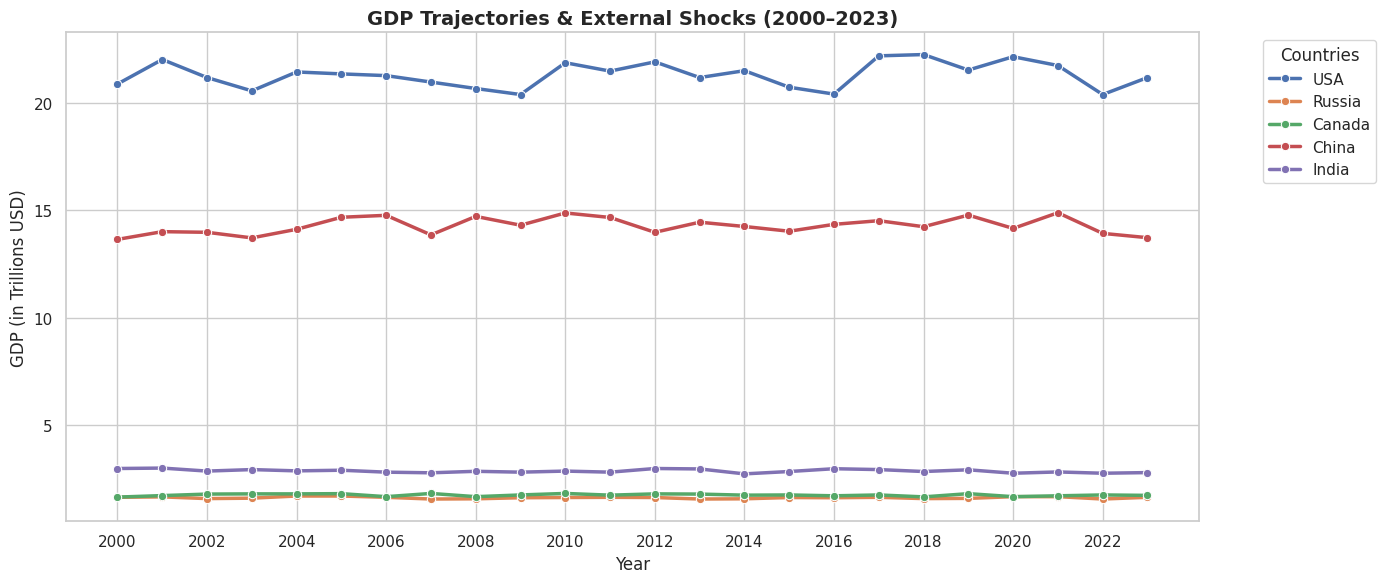

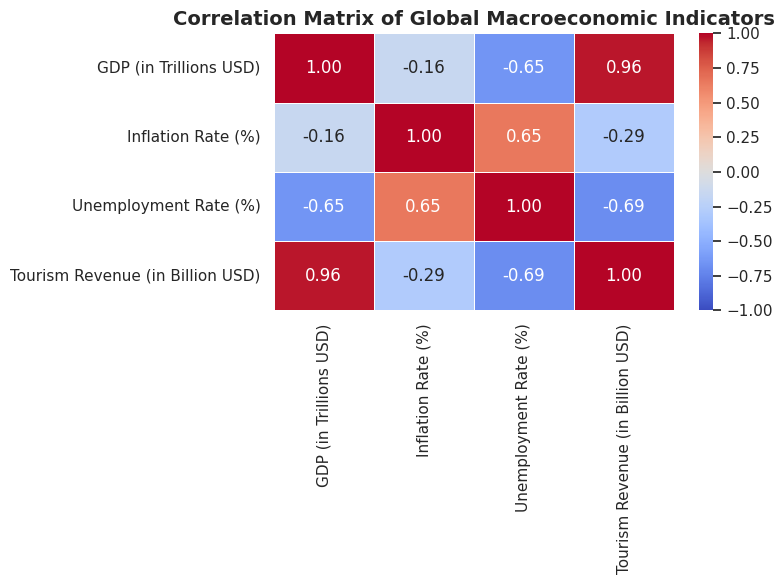

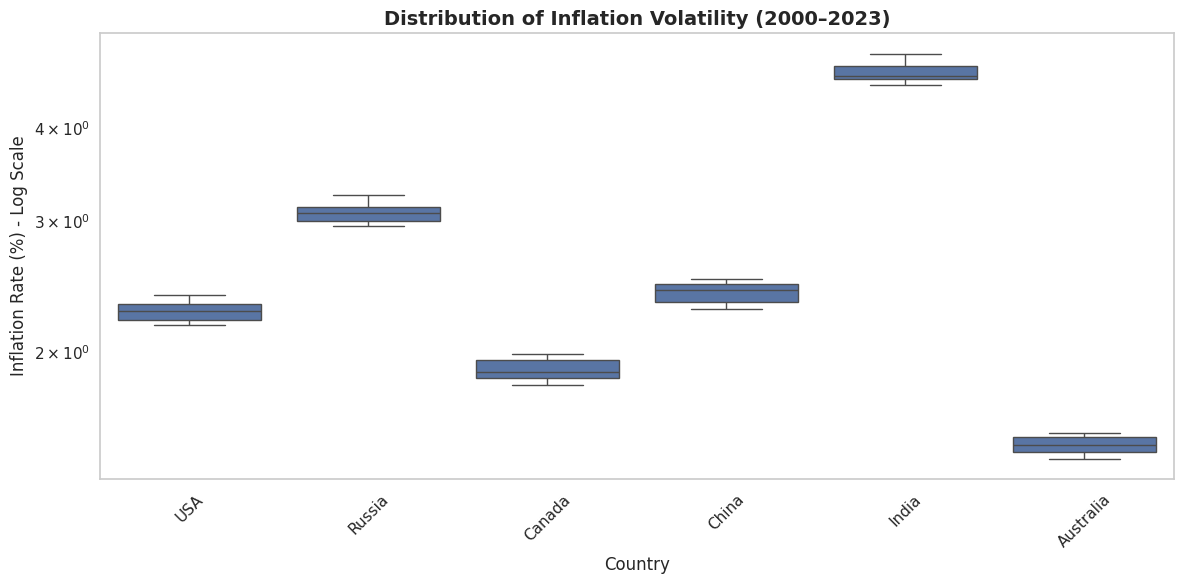

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set style for professional academic plotting
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

# ==========================================
# 1. DATA LOADING & CLEANING
# ==========================================

# Load dataset using its correct location
df = pd.read_csv('/content/Global Economic Data.csv')

# Filter for the capstone scope: 2000 to 2023
df = df[(df['Year'] >= 2000) & (df['Year'] <= 2023)]

# Display structural overview
print("--- Dataset Info ---")
print(df.info())
print("\n--- Missing Values Per Column ---")
print(df.isnull().sum())


# ==========================================
# 2. VISUALIZATION MAPS
# ==========================================

# --- Map A: Time-Series Line Plot (GDP Trajectories) ---
target_countries = df['Country'].unique()[:5]
df_filtered = df[df['Country'].isin(target_countries)]

plt.figure(figsize=(14, 6))
sns.lineplot(data=df_filtered, x='Year', y='GDP (in Trillions USD)', hue='Country', marker='o', linewidth=2.5)
plt.title('GDP Trajectories & External Shocks (2000–2023)', fontsize=14, fontweight='bold')
plt.xlabel('Year', fontsize=12)
plt.ylabel('GDP (in Trillions USD)', fontsize=12)
plt.xticks(range(2000, 2024, 2))
plt.legend(title='Countries', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()


# --- Map B: Correlation Heatmap (Macroeconomic Links) ---
plt.figure(figsize=(8, 6))
# Focus columns updated to match the exact names in the CSV
macro_cols = ['GDP (in Trillions USD)', 'Inflation Rate (%)', 'Unemployment Rate (%)', 'Tourism Revenue (in Billion USD)']
corr_matrix = df[macro_cols].corr()

sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5, vmin=-1, vmax=1)
plt.title('Correlation Matrix of Global Macroeconomic Indicators', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


# --- Map C: Distribution Box Plot (Regional Volatility) ---
# Note: Since 'Region' column is not in your df.info() list, we use 'Country' or another category.
# If your CSV does not have a 'Region' column, we will plot by 'Country'.
if 'Region' in df.columns:
    x_col = 'Region'
else:
    x_col = 'Country'

plt.figure(figsize=(12, 6))
sns.boxplot(data=df, x=x_col, y='Inflation Rate (%)')
plt.yscale('log') # Useful if you have hyperinflation outliers skewing the scale
plt.title('Distribution of Inflation Volatility (2000–2023)', fontsize=14, fontweight='bold')
plt.xlabel(x_col, fontsize=12)
plt.ylabel('Inflation Rate (%) - Log Scale', fontsize=12)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()